# 01 · Pre-trained models: OCR and zero-shot classification

**Goal.** Before training anything, see how far we get with models that are already trained:

1. **Tesseract OCR** reads a receipt photo and we pull out the *total* and the *date*.
2. **MiniLM** (a sentence-embedding model) guesses the category of an expense with **zero training**,
   just by comparing its meaning to a short description of each category.

The zero-shot score becomes the **number any trained model must beat**.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score

from src import config, data, ocr
from src.zero_shot import similarity_scores, zero_shot_predict

np.random.seed(config.RANDOM_SEED)
pd.set_option("display.max_colwidth", 80)

## Part A · OCR on receipt photos

The pipeline in `src/ocr.py`:

| Step | Why |
|---|---|
| Fix EXIF rotation | Phones store "rotate 90°" as a tag; Tesseract ignores it and reads sideways text as noise. |
| Grayscale | Colour adds nothing to reading text. |
| Upscale small images | Tesseract works best when letters are ~30 px tall. |
| Light blur + adaptive threshold | Turns the photo into clean black text on white, even with shadows. |
| Run Tesseract twice (`--psm 4`, `--psm 6`) | Two layout guesses; keep the one with more readable lines. |
| Regex for total and date | Look for "Grand Total / Net Payable / Total", skip "Sub Total / Tax / Cash / Change". |

### A1 · What the pre-processing does (demo image)

The image below is **generated in code** only to show the steps. It is *not* one of the labelled
receipts and is **not counted** in any accuracy number.

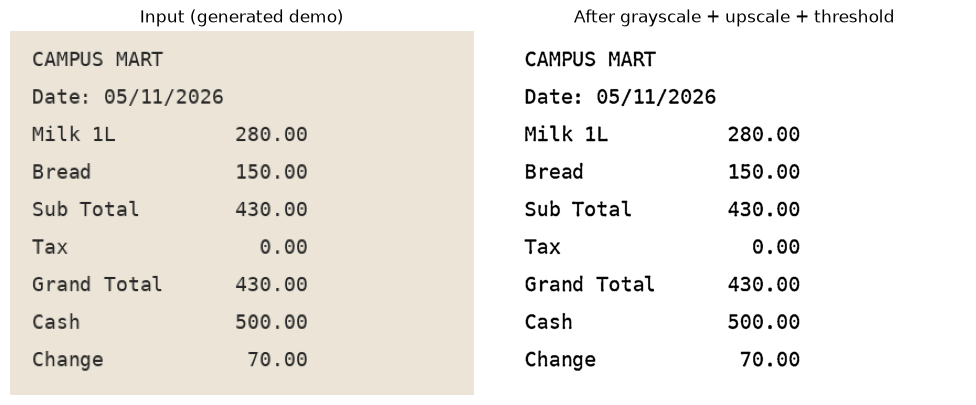

CAMPUS MART

Date: 05/11/2026

Milk 1L 280.00
Bread 150.00
Sub Total 430.00
Tax 0.00
Grand Total 430.00
Cash 500.00
Change 70.00

total -> 430.0 | date -> 2026-11-05


In [2]:
from PIL import Image, ImageDraw, ImageFont
import matplotlib.font_manager as fm

font = ImageFont.truetype(fm.findfont("DejaVu Sans Mono"), 18)
demo = Image.new("RGB", (420, 330), (235, 228, 215))  # off-white, like thermal paper
draw = ImageDraw.Draw(demo)
lines = ["CAMPUS MART", "Date: 05/11/2026", "Milk 1L          280.00", "Bread            150.00",
         "Sub Total        430.00", "Tax                0.00", "Grand Total      430.00",
         "Cash             500.00", "Change            70.00"]
for i, line in enumerate(lines):
    draw.text((20, 15 + i * 34), line, fill=(40, 40, 40), font=font)

processed = ocr.preprocess(demo)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(demo); axes[0].set_title("Input (generated demo)")
axes[1].imshow(processed, cmap="gray"); axes[1].set_title("After grayscale + upscale + threshold")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

text = ocr.run_tesseract(processed)
print(text)
print("total ->", ocr.extract_total(text), "| date ->", ocr.extract_date(text))

### A2 · Accuracy on the labelled receipts

`data/receipts/labels.csv` lists each photo with the **true** total and date, checked by hand.
A total counts as correct if it matches to the paisa; a date counts as correct if it is the same day.

In [3]:
labels = pd.read_csv(config.RECEIPT_LABELS_CSV)
print(f"Labelled receipts: {len(labels)}")

def check_receipt(row) -> dict:
    result = ocr.read_receipt(config.RECEIPTS_DIR / row.file)
    true_date = pd.to_datetime(row.date).strftime("%Y-%m-%d") if pd.notna(row.date) else None
    return {
        "file": row.file, "true_total": row.total, "ocr_total": result["total"],
        "true_date": true_date, "ocr_date": result["date"], "text": result["text"],
        "total_ok": result["total"] is not None and abs(result["total"] - row.total) < 0.01,
        "date_ok": result["date"] == true_date,
    }

ocr_results = pd.DataFrame([check_receipt(r) for r in labels.itertuples()])
if ocr_results.empty:
    print("No labelled receipts yet. Add photos to data/receipts/ and one row per photo to "
          "labels.csv, then re-run this notebook.")
else:
    print(f"Total correct: {ocr_results.total_ok.mean():.0%} ({ocr_results.total_ok.sum()}/{len(ocr_results)})")
    print(f"Date correct:  {ocr_results.date_ok.mean():.0%} ({ocr_results.date_ok.sum()}/{len(ocr_results)})")
    display(ocr_results.drop(columns="text"))

Labelled receipts: 0
No labelled receipts yet. Add photos to data/receipts/ and one row per photo to labels.csv, then re-run this notebook.


### A3 · Three receipts OCR gets wrong

Looking at failures tells us *why* OCR fails (blur, crumpled paper, unusual wording such as
"Payable Amount"), which is more useful than the percentage alone.

In [4]:
wrong = ocr_results[~(ocr_results.total_ok & ocr_results.date_ok)] if not ocr_results.empty else ocr_results
if wrong.empty:
    print("No wrong receipts to show (either no receipts yet, or OCR got every one right).")
for row in wrong.head(3).itertuples():
    fig, ax = plt.subplots(figsize=(4, 6))
    ax.imshow(ocr.load_image(config.RECEIPTS_DIR / row.file)); ax.axis("off")
    ax.set_title(f"{row.file}\ntrue total {row.true_total} / OCR {row.ocr_total}\n"
                 f"true date {row.true_date} / OCR {row.ocr_date}", fontsize=9)
    plt.show()
    print(row.text[:800])
    print("-" * 60)

No wrong receipts to show (either no receipts yet, or OCR got every one right).


## Part B · Zero-shot classification with MiniLM

MiniLM turns any sentence into a list of 384 numbers (an *embedding*). Sentences with similar
meaning get similar numbers. We embed one short description per category, embed each expense,
and pick the category whose description is **most similar** (cosine similarity). No training data is used.

We evaluate on the **test split**: the latest 20% of the household data by date, the same split
the trained models will be judged on later.

In [5]:
household = data.load_source("household")
train, test = data.time_split(household)
print(f"Train: {len(train)} rows, {train.date.min():%Y-%m-%d} to {train.date.max():%Y-%m-%d}")
print(f"Test:  {len(test)} rows, {test.date.min():%Y-%m-%d} to {test.date.max():%Y-%m-%d}")
pd.Series(config.CATEGORY_DESCRIPTIONS, name="description used for zero-shot").to_frame()

[map] household: dropped 444 of 2176 rows with no matching category
[clean] removed 159 empty-description rows and 0 exact duplicates
Train: 1258 rows, 2015-01-01 to 2018-03-15
Test:  315 rows, 2018-03-17 to 2018-09-20


,description used for zero-shot
Food,"Food: restaurant, lunch, dinner, snacks, tea, coffee, fast food, eating out"
Groceries,"Groceries: grocery store, milk, eggs, vegetables, fruit, bread, flour, super..."
Transport,"Transport: rickshaw, bus, train, taxi, fuel, petrol, ride-hailing, careem, uber"
Shopping,"Shopping: clothes, shoes, electronics, amazon, household items, appliances"
Bills,"Bills: electricity, gas, water, internet, mobile recharge, rent, subscription"
Health,"Health: medicine, pharmacy, doctor, hospital, lab test, clinic"
Education,"Education: books, stationery, course fee, exam fee, tuition, university"
Entertainment,"Entertainment: movie, cinema, netflix, music, games, outing, festival"


In [6]:
zs_pred = zero_shot_predict(test.description.tolist())
zs_acc = accuracy_score(test.category, zs_pred)
zs_f1 = f1_score(test.category, zs_pred, average="macro", labels=config.CATEGORIES, zero_division=0)
print(f"Zero-shot accuracy: {zs_acc:.3f}")
print(f"Zero-shot macro-F1: {zs_f1:.3f}   <- the number trained models must beat")

Zero-shot accuracy: 0.365
Zero-shot macro-F1: 0.310   <- the number trained models must beat


**Accuracy** is the share of expenses labelled correctly. **Macro-F1** averages the F1 score of
each category equally, so a rare category like Education counts as much as Food. We use
macro-F1 to pick models because a model that only gets the big categories right should not look good.

In [7]:
print(classification_report(test.category, zs_pred, labels=config.CATEGORIES, zero_division=0))

               precision    recall  f1-score   support

         Food       0.51      0.38      0.44        99
    Groceries       0.52      0.34      0.41        89
    Transport       0.20      0.32      0.25        50
     Shopping       0.35      0.45      0.39        29
        Bills       0.30      0.30      0.30        23
       Health       0.43      0.60      0.50        15
    Education       0.00      0.00      0.00         3
Entertainment       0.14      0.29      0.19         7

     accuracy                           0.37       315
    macro avg       0.31      0.33      0.31       315
 weighted avg       0.42      0.37      0.38       315



### B1 · A look inside: similarity scores for a few test expenses

In [8]:
sample = test.sample(8, random_state=config.RANDOM_SEED)
scores = pd.DataFrame(similarity_scores(sample.description.tolist()),
                      columns=config.CATEGORIES, index=sample.description).round(2)
scores["predicted"] = scores[config.CATEGORIES].idxmax(axis=1)
scores["true"] = sample.category.values
scores

,Food,Groceries,Transport,Shopping,Bills,Health,Education,Entertainment,predicted,true
description,,,,,,,,,,
At restaurant,0.45,0.26,0.14,0.32,0.12,0.23,0.10,0.32,Food,Food
Bread,0.33,0.51,0.17,0.17,0.11,0.14,0.09,0.03,Groceries,Food
Place 0 to Place 4 return,0.10,0.02,0.05,-0.01,-0.01,0.02,-0.11,0.05,Food,Transport
milk 1lit,0.19,0.22,0.12,0.07,0.11,0.12,-0.02,0.09,Groceries,Groceries
Home Food Delivery,0.45,0.47,0.22,0.30,0.16,0.16,0.09,0.12,Groceries,Food
onion 1 kg,0.14,0.14,-0.03,0.04,0.05,-0.01,0.02,-0.06,Food,Groceries
IKEA tea 3,0.38,0.17,0.19,0.26,0.11,0.14,0.01,0.13,Food,Food
Station Parking,0.13,0.12,0.26,0.14,0.17,0.05,0.02,0.18,Transport,Transport


## What I learned